In [274]:
import math
import torch
import random

In [249]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [11]:
class Value():

    def __init__(self, data, _op='', _children=(), label=''):
        self.data = data
        self.label = label
        self._op = _op
        self._prev = set(_children)
        self.grad = 0.0
        self._backward = lambda: None


    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, '+', (self, other))

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward

        return out

    def __radd__(self, other): # other + self
        return self + other        

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, '*', (self, other))

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other): # other * self
        return self * other

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, 'tanh', (self, ))

        def _backward():
            self.grad += (1 - t**2) * out.grad

        out._backward = _backward

        return out

    def relu(self):
        out = Value(0 if self.data < 0 else self.data, 'ReLU', (self,))

        def _backward():
            self.grad += (out.data > 0) * out.grad
        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, f'**{other}', (self,))

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad

        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), 'exp', (self, ))
        
        def _backward():
            self.grad += out.data * out.grad
        
        out._backward = _backward
    
        return out

    def __truediv__(self, other):
        return self * other**-1

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __rtruediv__(self, other):
        return other * self**-1

    def backward(self):
        topo = []
        visited = set()
        
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)
        
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

    def __repr__(self):
        return f"{self.label} : Value {self.data}"

In [4]:
a = Value(2, label='a')
b = Value(3, label='b')

c = a + b; c.label = 'c'

d = Value(10, label='d')

e = c * d; e.label = 'e'

f = Value(1, label='f')

L = e + f; L.label = 'L'

In [5]:
L.backward()

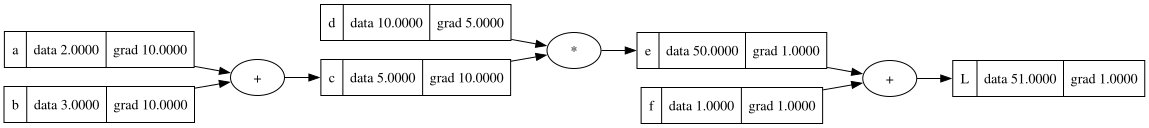

In [253]:
draw_dot(L)

In [254]:
a.data += -0.01 * a.grad
b.data += -0.01 * b.grad
d.data += -0.01 * d.grad
f.data += -0.01 * f.grad


c = a + b; c.label = 'c'
e = c * d; e.label = 'e'
L = e + f; L.label = 'L'

L.data


48.75

In [255]:
x1 = Value(2, label='x1')
x2 = Value(-4, label='x2')

w1 = Value(2, label='w1')
w2 = Value(2, label='w2')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'

b = Value(9, label='b')

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'

n = x1w1x2w2 + b; n.label = 'n'

f = n.tanh(); f.label = 'f'
f.backward()

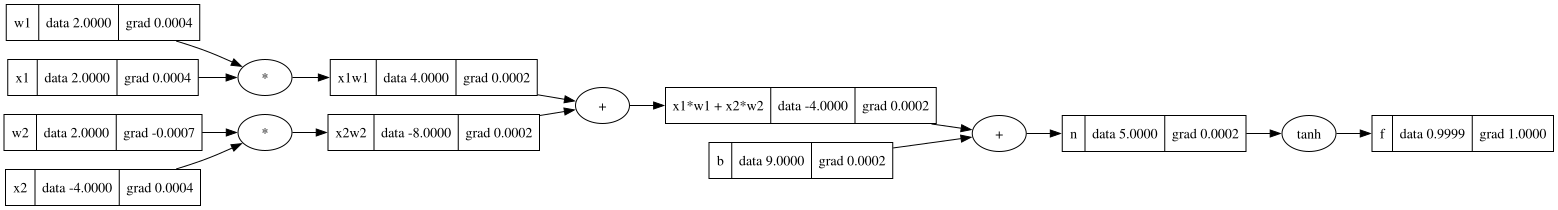

In [256]:
draw_dot(f)

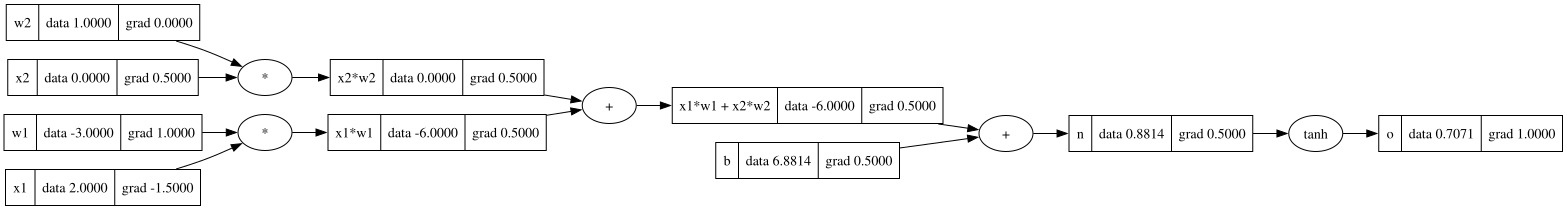

In [ ]:
# # inputs x1,x2
# x1 = Value(2.0, label='x1')
# x2 = Value(0.0, label='x2')
# # weights w1,w2
# w1 = Value(-3.0, label='w1')
# w2 = Value(1.0, label='w2')
# # bias of the neuron
# b = Value(6.8813735870195432, label='b')
# # x1*w1 + x2*w2 + b
# x1w1 = x1*w1; x1w1.label = 'x1*w1'
# x2w2 = x2*w2; x2w2.label = 'x2*w2'
# x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
# n = x1w1x2w2 + b; n.label = 'n'
# o = n.tanh(); o.label = 'o'
# o.backward()

# draw_dot(o)

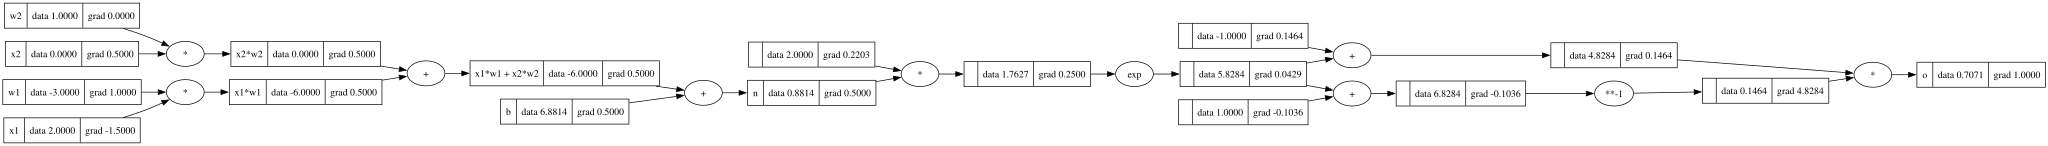

In [ ]:
# # inputs x1,x2
# x1 = Value(2.0, label='x1')
# x2 = Value(0.0, label='x2')
# # weights w1,w2
# w1 = Value(-3.0, label='w1')
# w2 = Value(1.0, label='w2')
# # bias of the neuron
# b = Value(6.8813735870195432, label='b')
# # x1*w1 + x2*w2 + b
# x1w1 = x1*w1; x1w1.label = 'x1*w1'
# x2w2 = x2*w2; x2w2.label = 'x2*w2'
# x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
# n = x1w1x2w2 + b; n.label = 'n'
# # ----
# e = (2*n).exp()
# o = (e - 1) / (e + 1)
# # ----
# o.label = 'o'
# o.backward()
# draw_dot(o)

In [269]:
x1 = torch.tensor(2.0).double(); x1.requires_grad = True
x2 = torch.tensor(0.0).double(); x2.requires_grad = True
w1 = torch.tensor(-3.0).double(); w1.requires_grad = True
w2 = torch.tensor(1.0).double(); w2.requires_grad = True
b = torch.tensor(6.8813735870195432).double(); b.requires_grad = True

n = x1*w1 + x2*w2 + b

f = torch.tanh(n)

print(f.data.item())
f.backward()


0.7071066904050358


In [273]:
print(x1.grad.item())
print(x2.grad.item())
print(w1.grad.item())
print(w2.grad.item())

-1.5000003851533106
0.5000001283844369
1.0000002567688737
0.0


In [349]:
class Neuron():

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x):
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()

        return out

    def parameters(self):
        return [self.b] + self.w


class Layer():

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [out(x) for out in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]


class MLP():

    def __init__(self, nin, nouts):
        li = [nin] + nouts
        self.layers = [Layer(li[i], li[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)

        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
        

In [350]:
n = Neuron(2)
n([1, 2])

n.parameters()

[ : Value 0.5708252634625155,
  : Value -0.5786253337274967,
  : Value 0.515679632390122]

In [351]:
l = Layer(2, 3)
out, _, _ = l([1, 2])

l.parameters()

[ : Value -0.316681684855167,
  : Value -0.7641122421212474,
  : Value -0.5458585018370312,
  : Value -0.7051867796887104,
  : Value 0.09375547484110291,
  : Value 0.9450960054819557,
  : Value -0.9827117076359435,
  : Value 0.9563130257875327,
  : Value -0.8609401255742597]

In [354]:
mlp = MLP(2, [3, 3, 2])
mlp([1, 2])

mlp.parameters()

[ : Value 0.21599334970886508,
  : Value -0.5304291610493339,
  : Value -0.17494971461501985,
  : Value 0.01797527234604379,
  : Value -0.11922035509341433,
  : Value 0.4038460045926693,
  : Value -0.6748002978858736,
  : Value -0.8777275532187787,
  : Value -0.5167791470795304,
  : Value 0.06465888097576444,
  : Value -0.10218747330185085,
  : Value -0.890953242266475,
  : Value -0.0666415934742397,
  : Value -0.7056218323037882,
  : Value 0.5758538183581343,
  : Value -0.6812129397956503,
  : Value 0.771747843231654,
  : Value -0.6345514892835424,
  : Value 0.1213815391277977,
  : Value 0.22567771552369376,
  : Value -0.35762697233216567,
  : Value 0.8638557363160768,
  : Value 0.9620566118222762,
  : Value -0.08810405336478166,
  : Value -0.165899881151504,
  : Value 0.08215464340196021,
  : Value -0.7482456147273919,
  : Value 0.6866226517649285,
  : Value 0.17547551630541558]

In [355]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [366]:
mlp = MLP(3, [4, 4, 1])

ypred = [mlp(x) for x in xs]

In [367]:
ypred

[ : Value -0.9425270341223544,
  : Value -0.8888499825715239,
  : Value -0.8596932640410717,
  : Value -0.7853650088834316]

In [373]:
loss = sum((ypred - ys)**2 for ys, ypred in zip(ys, ypred))

In [376]:
loss

 : Value 6.992979799771325

In [407]:
for k in range(10):
    # forward pass
    ypred = [mlp(x) for x in xs]

    # calculate loss
    loss = sum((ypred - ys)**2 for ys, ypred in zip(ys, ypred))

    # do backward pass for gradients : need to make grads zero so they don't accumulate
    for p in mlp.parameters():
        p.grad = 0.0
    loss.backward()

    for p in mlp.parameters():
        p.data -= 0.01 * p.grad

loss

 : Value 0.013094371429996815

In [408]:
ypred

[ : Value 0.9440293378487942,
  : Value -0.9376725209230456,
  : Value -0.951764656798611,
  : Value 0.9387603606598763]

In [2]:
from test_engine import test_more_ops, test_sanity_check

test_sanity_check()
test_more_ops()